In [2]:
%pip install mne

Note: you may need to restart the kernel to use updated packages.


In [4]:
import mne

In [5]:
import pandas as pd

In [6]:
import matplotlib.pyplot as plt

In [8]:
import os
print(os.getcwd())
print(os.path.exists("S001R04.edf"))

C:\Users\Tejasree
True


In [9]:
from scipy.stats import ttest_ind

In [10]:
file_path ="S001R04.edf"

raw = mne.io.read_raw_edf(file_path, preload=True)

print(raw)
print("Sampling_frequency:", raw.info["sfreq"], "Hz")
print("Number of channels:", len(raw.ch_names))

Extracting EDF parameters from S001R04.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...
<RawEDF | S001R04.edf, 64 x 20000 (125.0 s), ~9.8 MiB, data loaded>
Sampling_frequency: 160.0 Hz
Number of channels: 64


In [12]:
raw_original = raw.copy()
raw_filtered = raw.copy()

In [13]:
print("Original EEG:", raw_original)
print("Filtered EEG before filtering:", raw_filtered)

Original EEG: <RawEDF | S001R04.edf, 64 x 20000 (125.0 s), ~9.8 MiB, data loaded>
Filtered EEG before filtering: <RawEDF | S001R04.edf, 64 x 20000 (125.0 s), ~9.8 MiB, data loaded>


In [20]:
print("raw exists:", "raw" in globals())

raw exists: True


In [21]:
raw_original= raw.copy()
raw_filtered= raw.copy()

print("Copies created successfully!")
print(type(raw_filtered))


Copies created successfully!
<class 'mne.io.edf.edf.RawEDF'>


In [23]:
raw_filtered.filter(l_freq=1.0, h_freq=40.0, picks="eeg")

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 529 samples (3.306 s)



<RawEDF | S001R04.edf, 64 x 20000 (125.0 s), ~9.8 MiB, data loaded>

In [24]:
print(raw_original.annotations)

<Annotations | 30 segments: T0 (15), T1 (8), T2 (7)>


In [26]:
from collections import Counter
print(Counter(raw_original.annotations.description))

Counter({'T0': 15, 'T1': 8, 'T2': 7})


In [27]:
annotations_table = pd.DataFrame({"Onset_seconds": raw_original.annotations.onset,
                                  "Duration_seconds": raw_original.annotations.duration,
                                  "Label": raw_original.annotations.description})

In [29]:
print(annotations_table.head(15))

    Onset_seconds  Duration_seconds Label
0             0.0               4.2    T0
1             4.2               4.1    T2
2             8.3               4.2    T0
3            12.5               4.1    T1
4            16.6               4.2    T0
5            20.8               4.1    T1
6            24.9               4.2    T0
7            29.1               4.1    T2
8            33.2               4.2    T0
9            37.4               4.1    T2
10           41.5               4.2    T0
11           45.7               4.1    T1
12           49.8               4.2    T0
13           54.0               4.1    T2
14           58.1               4.2    T0


Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


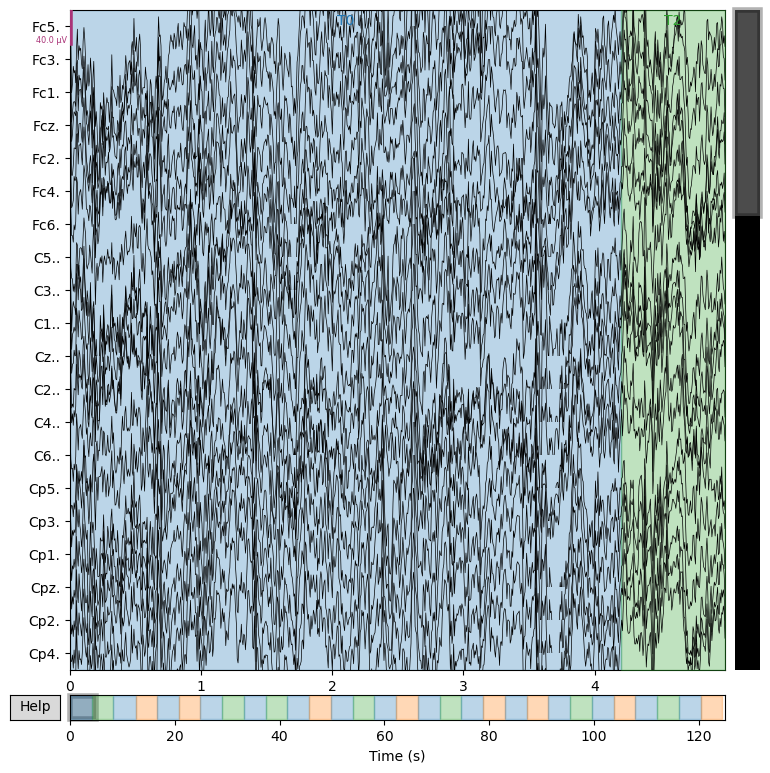

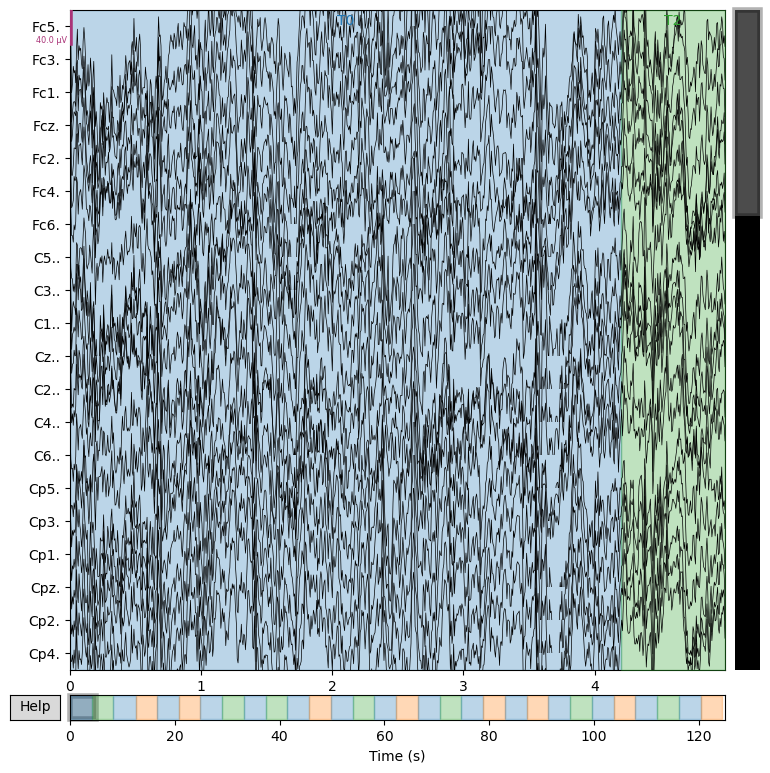

In [30]:
raw_original.plot(duration=5, title="Original EEG")

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


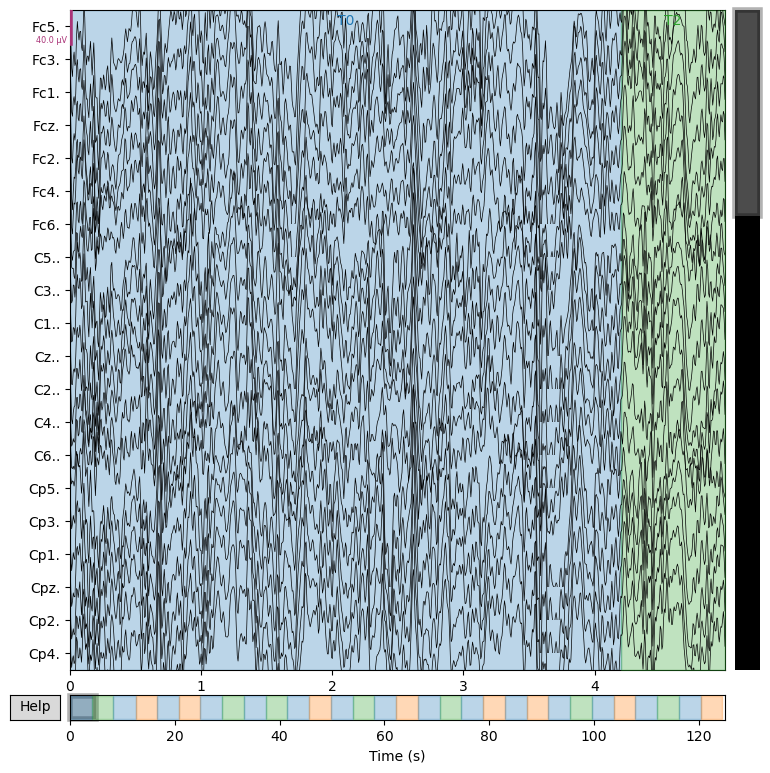

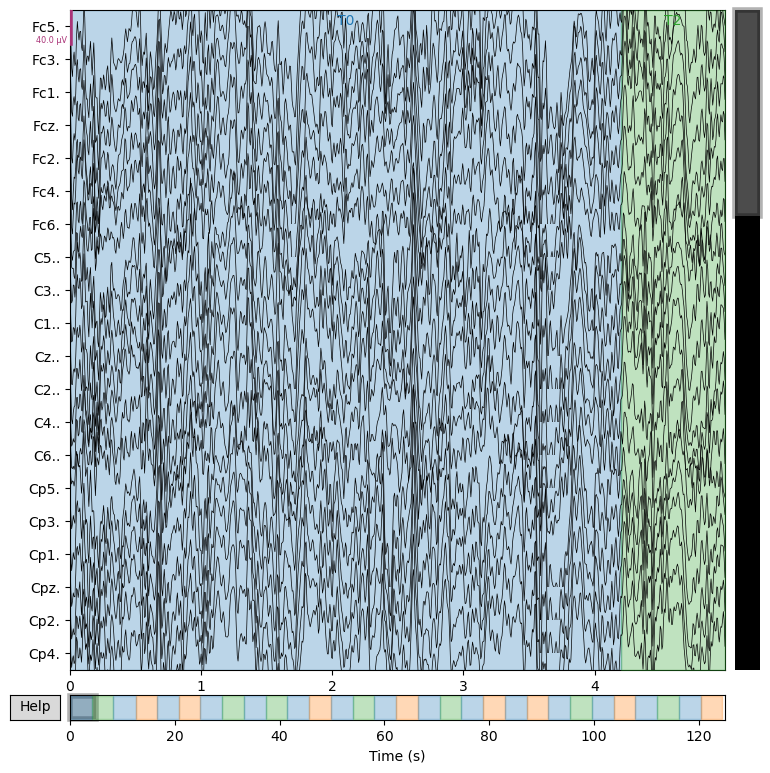

In [31]:
raw_filtered.plot(duration=5, title="Filtered EEG: 1-40 Hz")

Effective window size : 12.800 (s)
Plotting power spectral density (dB=True).


C:\Users\Tejasree\AppData\Local\Temp\ipykernel_5324\1198165675.py:4: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  picks= "eeg").plot()


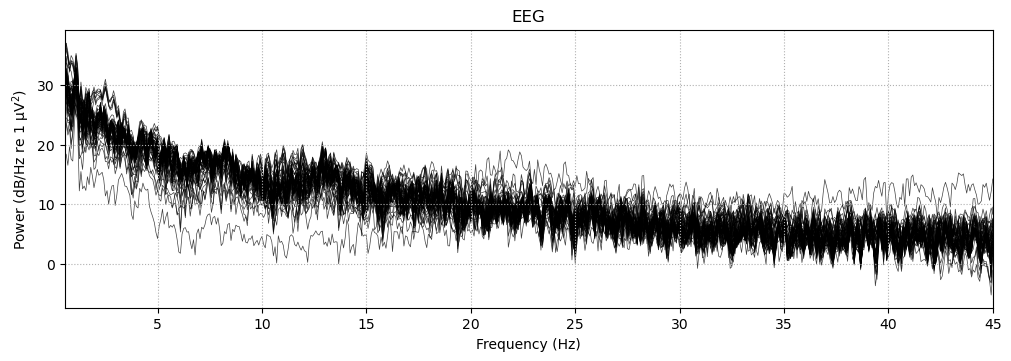

Effective window size : 12.800 (s)
Plotting power spectral density (dB=True).


C:\Users\Tejasree\AppData\Local\Temp\ipykernel_5324\1198165675.py:9: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  picks ="eeg").plot()


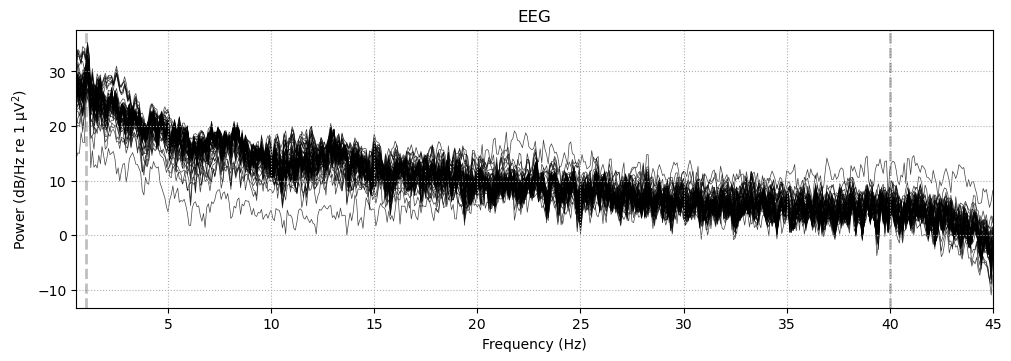

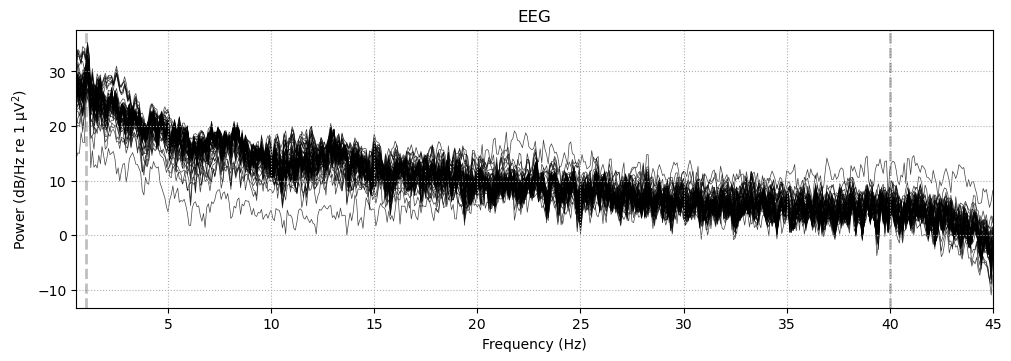

In [35]:
raw_original.compute_psd( method="welch", 
                          fmin= 0.5,
                          fmax= 45, 
                          picks= "eeg").plot()

raw_filtered.compute_psd(method= "welch",
                         fmin=0.5,
                        fmax= 45,
                         picks ="eeg").plot()
                          

In [15]:
events, event_id = mne.events_from_annotations(raw_filtered)

print("Event mapping:", event_id)
print("First five events:")
print(events[:5])


Used Annotations descriptions: ['T0', 'T1', 'T2']
Event mapping: {'T0': 1, 'T1': 2, 'T2': 3}
First five events:
[[   0    0    1]
 [ 672    0    3]
 [1328    0    1]
 [2000    0    2]
 [2656    0    1]]


In [37]:
print(event_id)

{'T0': 1, 'T1': 2, 'T2': 3}


In [16]:
print("MNE version:",  mne.__version__)
print("Epoch start:", -0.5)
print("Epoch end:", 4.0)
print("Baseline test:", (-0.5, 0.0))

MNE version: 1.13.2
Epoch start: -0.5
Epoch end: 4.0
Baseline test: (-0.5, 0.0)


In [17]:
selected_events ={"T1": event_id["T1"],
                  "T2": event_id["T2"]}

epochs = mne.Epochs( raw_filtered,
                     events,
                     event_id=selected_events,
                     tmin= -0.5,
                     tmax= 4.0,
                     baseline= (-0.5,0.0),
                     preload=True,
                     reject_by_annotation= True)

print(epochs)
print("Number of T1 epochs:", len(epochs["T1"]))
print("Number of T2 epochs:", len(epochs["T2"]))

Not setting metadata
15 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 15 events and 721 original time points ...
0 bad epochs dropped
<Epochs | 15 events (all good), -0.5 – 4 s (baseline -0.5 – 0 s), ~5.3 MiB, data loaded,
 'T1': 8
 'T2': 7>
Number of T1 epochs: 8
Number of T2 epochs: 7


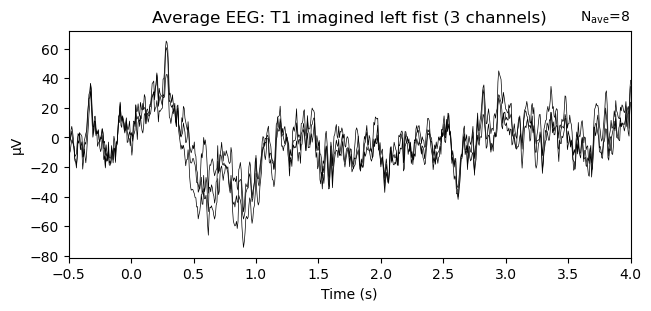

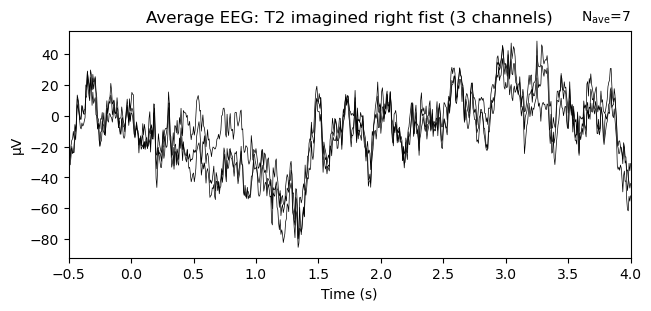

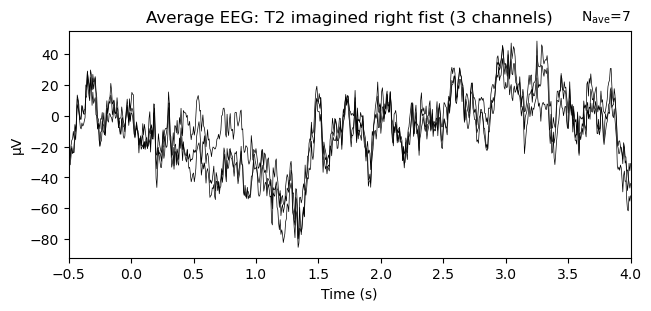

In [18]:
evoked_T1 = epochs["T1"].average()
evoked_T2 = epochs["T2"].average()

evoked_T1.plot( picks=['C3..', 'Cz..', 'C4..'], titles="Average EEG: T1 imagined left fist")

evoked_T2.plot( picks=['C3..','Cz..', 'C4..'], titles= "Average EEG: T2 imagined right fist")

In [19]:
print(raw_filtered.ch_names)

['Fc5.', 'Fc3.', 'Fc1.', 'Fcz.', 'Fc2.', 'Fc4.', 'Fc6.', 'C5..', 'C3..', 'C1..', 'Cz..', 'C2..', 'C4..', 'C6..', 'Cp5.', 'Cp3.', 'Cp1.', 'Cpz.', 'Cp2.', 'Cp4.', 'Cp6.', 'Fp1.', 'Fpz.', 'Fp2.', 'Af7.', 'Af3.', 'Afz.', 'Af4.', 'Af8.', 'F7..', 'F5..', 'F3..', 'F1..', 'Fz..', 'F2..', 'F4..', 'F6..', 'F8..', 'Ft7.', 'Ft8.', 'T7..', 'T8..', 'T9..', 'T10.', 'Tp7.', 'Tp8.', 'P7..', 'P5..', 'P3..', 'P1..', 'Pz..', 'P2..', 'P4..', 'P6..', 'P8..', 'Po7.', 'Po3.', 'Poz.', 'Po4.', 'Po8.', 'O1..', 'Oz..', 'O2..', 'Iz..']


In [20]:
motor_channels = ['C3..', 'Cz..','C4..']

print("Available motor channels:")
print([ch for ch in motor_channels if ch in raw_filtered.ch_names])

Available motor channels:
['C3..', 'Cz..', 'C4..']


In [21]:
spectrum = epochs.compute_psd(
    method="welch",
    picks=motor_channels,
    fmin=8,
    fmax=30,
    n_per_seg=256,
    n_overlap=128
)
psd_data, freqs = spectrum.get_data(return_freqs=True)

print("PSD array shape:", psd_data.shape)
print("Frequency array shape:", freqs.shape)

Effective window size : 4.506 (s)
PSD array shape: (15, 3, 99)
Frequency array shape: (99,)


In [22]:
mu_mask = (freqs >= 8) & (freqs <13)
beta_mask = (freqs >=13) & (freqs <=30)

frequency_step = freqs[1] - freqs[0]

mu_power =psd_data[:,:, mu_mask].sum(axis=-1)*frequency_step
beta_power=psd_data[:,:,beta_mask].sum(axis=-1)*frequency_step

# Convert power from V² to µV²
mu_power = mu_power* 1e12
beta_power = beta_power * 1e12

print("Mu power shape:", mu_power.shape)
print("Beta power shape:", beta_power.shape)

Mu power shape: (15, 3)
Beta power shape: (15, 3)


In [23]:
t1_mask = epochs.events[:,2]==event_id["T1"]
t2_mask = epochs.events[:,2]==event_id["T2"]

mu_T1 =mu_power[t1_mask]
mu_T2 =mu_power[t2_mask]

beta_T1 = beta_power[t1_mask]
beta_T2 = beta_power[t2_mask]

print("T1 mu power shape:", mu_T1.shape)
print("T2 mu power shape:", mu_T2.shape)

T1 mu power shape: (8, 3)
T2 mu power shape: (7, 3)


In [24]:
results=[]

for i, channel in enumerate(motor_channels):
    results.append({
    "channel": channel,
    "T1_mu_mean": mu_T1[:, i].mean(),
    "T2_mu_mean": mu_T2[:,i].mean(), 
    "T1_beta_mean": beta_T1[:,i].mean(),
    "T2_beta_mean": beta_T2[:,i].mean()})

results_df =pd.DataFrame(results)

print(results_df.round(3))

  channel  T1_mu_mean  T2_mu_mean  T1_beta_mean  T2_beta_mean
0    C3..     162.842     127.219       193.631       183.309
1    Cz..     160.537     144.546       186.102       168.268
2    C4..     112.154     136.409       140.199       141.950


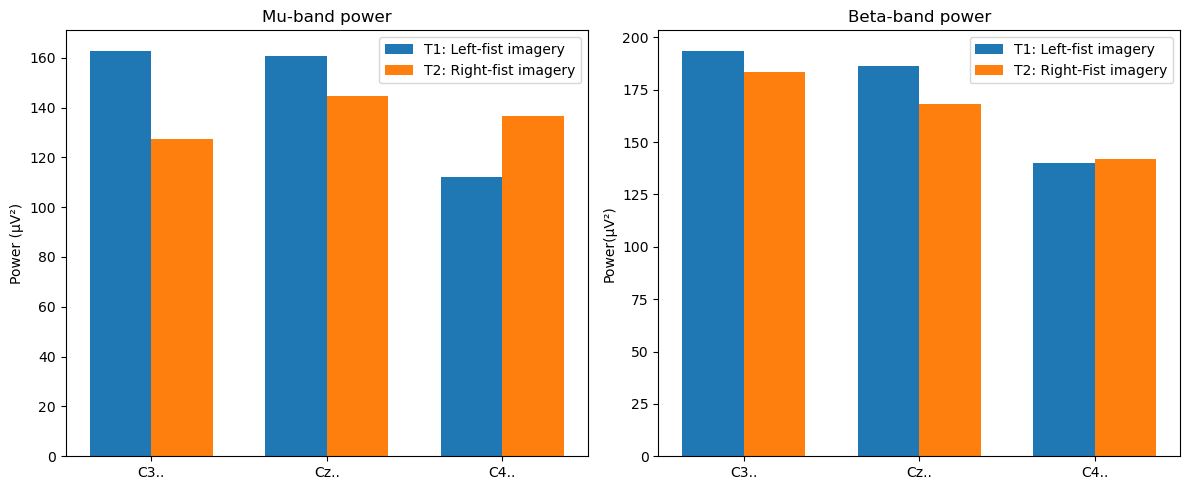

In [25]:
x= np.arange(len(motor_channels))
width = 0.35

fig,axes =plt.subplots(1,2,figsize=(12,5))

axes[0].bar(
    x- width/2, 
    mu_T1.mean(axis=0),
    width,
    label="T1: Left-fist imagery")
axes[0].bar(
    x+ width/2,
    mu_T2.mean(axis=0),
    width,
    label="T2: Right-fist imagery")
axes[0].set_title("Mu-band power")
axes[0].set_xticks(x)
axes[0].set_xticklabels(motor_channels)
axes[0].set_ylabel("Power (µV²)")
axes[0].legend()

axes[1].bar(
    x-width/2,
    beta_T1.mean(axis=0),
    width,
    label="T1: Left-fist imagery")
axes[1].bar(
    x+width/2, 
    beta_T2.mean(axis=0),
    width,
    label="T2: Right-Fist imagery")
axes[1].set_title("Beta-band power")
axes[1].set_xticks(x)
axes[1].set_xticklabels(motor_channels)
axes[1].set_ylabel("Power(µV²)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [26]:
for i, channel in enumerate(motor_channels):
    mu_test = ttest_ind(
        mu_T1[:,i],
        mu_T2[:,i],
        equal_var=False
    )

    beta_test = ttest_ind(
    beta_T1[:,i],
    beta_T2[:,i],
    equal_var=False
    )

    print(f"\nChannel: {channel}")
    print(f"Mu-band p-value: {mu_test.pvalue:.4f}")
    print(f"Beta-band p-value: {beta_test.pvalue:.4f}")


Channel: C3..
Mu-band p-value: 0.0718
Beta-band p-value: 0.6515

Channel: Cz..
Mu-band p-value: 0.2881
Beta-band p-value: 0.2950

Channel: C4..
Mu-band p-value: 0.2759
Beta-band p-value: 0.9042


In [32]:
import pandas as pd

results_table = pd.DataFrame({
    "Channel": ["C3", "Cz", "C4"],
    "Mu p-value": [0.0718, 0.2881, 0.2759],
    "Beta p-value": [ 0.6515, 0.2950, 0.9042]
})

display(results_table)

,Channel,Mu p-value,Beta p-value
0,C3,0.0718,0.6515
1,Cz,0.2881,0.2950
2,C4,0.2759,0.9042


### Interpretation of Statistical Results

Welch's independent-samples t-tests were performed to compare mu-band (8–13 Hz) and beta-band (13–30 Hz) power between the T1 and T2 conditions at the C3, Cz, and C4 EEG channels. None of the six comparisons reached the conventional significance threshold of p < 0.05. The results therefore provide no statistically significant evidence of a difference in mu- or beta-band power between the two motor-imagery conditions in this analysis.

These findings should be considered exploratory because the analysis used epochs from a single participant's recording. Epochs from the same recording may not be statistically independent, and the small number of channels and comparisons limits the conclusions that can be drawn.
